# Employee Data Analysis – Part 2: Visualisations, Report and Presentation
**Python & Data Engineering · Week 1 · Day 5 · Weekly Project**

## 1. Project Introduction
Part 1 (`week1/day5/task1_data_cleaning` and `task2_exploratory_analysis`) cleaned the employee dataset and explored it with tables.
Part 2 turns that cleaned data into **five charts**, a **one-page summary report**, an **HTML export** of this notebook,
a **Streamlit dashboard** and a **five-minute presentation**.

All chart code lives in one shared module, `src/employee_report.py`. This notebook, the saved PNG files and the Streamlit app
all call the same functions, so they always show the same numbers.

## 2. Problem Statement
Management wants to understand **how salaries are distributed across departments and cities**:
* Which departments pay the most and the least?
* Is pay spread evenly, or concentrated in a few people?
* Are there unusual (outlier) salaries?
* What should be investigated or changed next?

## 3. Dataset Overview
| Item | Value |
|---|---|
| File | `week1/day5/task1_data_cleaning/data/clean_data.csv` (output of Part 1 `cleaning.py`, **not copied**) |
| Original | `week1/day5/task1_data_cleaning/data/employees.csv` (the Day 4 training dataset) |
| Columns | `id`, `name`, `department`, `salary`, `city`, `salary_outlier` (flag added in Part 1) |
| Not available | experience, joining date, age, job level, salary currency and pay period |

> **Changes to the requested charts (the columns do not exist):**
> * *Experience vs salary* scatter → **Salary by city** scatter: each employee is a point, labelled with name and department.
> * *Hiring trend over time* line chart → **Payroll concentration curve**: a line showing what share of total payroll goes to the lowest-paid X % of staff.
>
> No experience values or dates were invented. Both replacements use real columns only.

## 4. Data Loading
The project folder (`week1/day5/afternoon`) is found automatically as the folder that contains `src/employee_report.py`, so the notebook runs on any computer
without hard-coded paths. `load_clean_data()` reads the Part 1 output. If that file were missing, it would re-run the Part 1 cleaning pipeline instead.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Find the repository root, wherever the notebook is opened from
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "employee_report.py").is_file())
sys.path.insert(0, str(ROOT / "src"))
import employee_report as er   # shared loading + chart functions

er.apply_style()               # one consistent style for every chart
pd.set_option("display.float_format", "{:,.0f}".format)

df = er.load_clean_data()
REPO = er.DAY5_DIR.parents[1]   # repository root, used only to print short paths
print(f"Loaded {len(df)} rows x {df.shape[1]} columns from {er.CLEAN_FILE.relative_to(REPO)}")
df

Loaded 8 rows x 6 columns from week1\day5\task1_data_cleaning\data\clean_data.csv


,id,name,department,salary,city,salary_outlier
0,1,Arun,Sales,65000,Chennai,False
1,2,Priya,HR,45000,Bangalore,False
2,3,Karthik,IT,58000,Chennai,False
3,4,Divya,IT,75000,Mumbai,False
4,5,Rohan,Finance,81000,Chennai,False
5,6,Meena,Sales,52000,Bangalore,False
6,7,Suresh,IT,68000,Hyderabad,False
7,8,Anitha,HR,48000,Mumbai,False


## 5. Data Preparation
Before charting, check the column types, missing values and duplicates. Then confirm that the saved file still matches
what the **Part 1 cleaning pipeline** produces today (re-using `cleaning.py`, not rewriting it).

In [2]:
print("Column data types:")
print(df.dtypes.to_string())
print(f"\nMissing values: {df.isna().sum().sum()} | Duplicate rows: {df.duplicated().sum()} | Duplicate ids: {df['id'].duplicated().sum()}")

# Re-run Part 1 cleaning on the raw file and compare with the saved clean_data.csv
sys.path.insert(0, str(er.PART1_DIR / "src"))
import cleaning
rerun, _ = cleaning.clean(cleaning.load_data())
same = rerun.astype(str).reset_index(drop=True).equals(df.astype(str))
print(f"Saved clean_data.csv matches a fresh run of the Part 1 pipeline: {same}")

missing_for_brief = [c for c in ["experience", "years_experience", "joining_date", "hire_date"] if c not in df.columns]
print(f"Columns requested by the brief but not in the data: {missing_for_brief}")

Column data types:
id                int64
name                str
department          str
salary            int64
city                str
salary_outlier     bool

Missing values: 0 | Duplicate rows: 0 | Duplicate ids: 0
Saved clean_data.csv matches a fresh run of the Part 1 pipeline: True
Columns requested by the brief but not in the data: ['experience', 'years_experience', 'joining_date', 'hire_date']


## 6. Exploratory Data Analysis
Summary statistics for `salary` (the only numeric measure, because `id` is just an identifier), then group comparisons and the IQR outlier check.

In [3]:
dept = er.group_summary(df, "department")
city = er.group_summary(df, "city")
bounds = er.iqr_bounds(df["salary"])
outliers = df[(df["salary"] < bounds["lower"]) | (df["salary"] > bounds["upper"])]

print("Salary summary statistics:")
print(df["salary"].describe().to_string(float_format="{:,.0f}".format))
print(f"\nIQR fences: {bounds['lower']:,.0f} to {bounds['upper']:,.0f} -> {len(outliers)} outlier(s)")
print("\nBy department:")
display(dept)
print("By city:")
display(city)

Salary summary statistics:
count        8
mean    61,500
std     12,950
min     45,000
25%     51,000
50%     61,500
75%     69,750
max     81,000

IQR fences: 22,875 to 97,875 -> 0 outlier(s)

By department:


,employees,avg_salary,median_salary,min_salary,max_salary
department,,,,,
Finance,1,"81,000","81,000",81000,81000
IT,3,"67,000","68,000",58000,75000
Sales,2,"58,500","58,500",52000,65000
HR,2,"46,500","46,500",45000,48000


By city:


,employees,avg_salary,median_salary,min_salary,max_salary
city,,,,,
Chennai,3,"68,000","65,000",58000,81000
Hyderabad,1,"68,000","68,000",68000,68000
Mumbai,2,"61,500","61,500",48000,75000
Bangalore,2,"48,500","48,500",45000,52000


### Chart helper
Each visualization below calls `show_and_save()`: it draws the chart with the shared module, saves a 200-dpi PNG to
`reports/figures/`, displays it, and prints the insight sentence (computed from the data, not typed by hand).

In [4]:
saved_files = []

def show_and_save(chart_function, filename, insight):
    fig = chart_function(df)
    path = er.save_figure(fig, filename)
    saved_files.append(path)
    plt.show()
    print(f"Saved: {path.relative_to(ROOT)}")
    print(f"Insight: {insight}")

## 7. Visualization 1 – Bar Chart: Average Salary by Department
Compares the average salary of each department against the company average. `n` shows how many employees sit behind each bar.

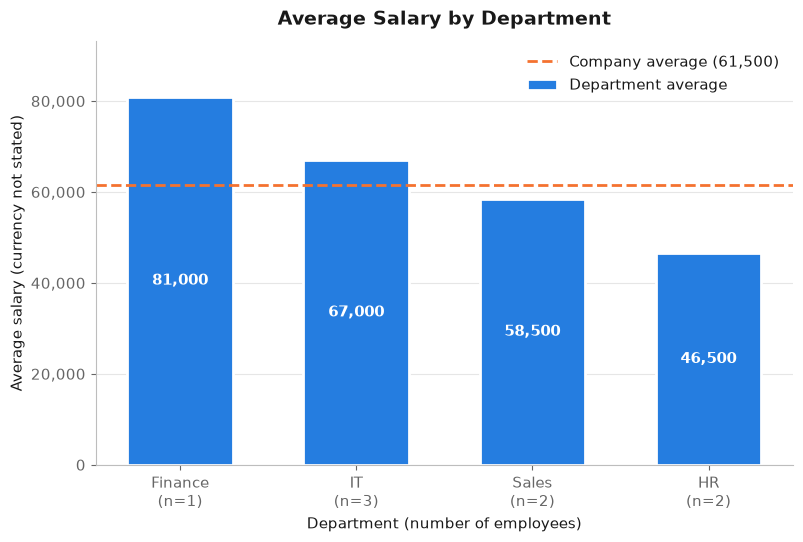

Saved: reports\figures\01_department_salary_bar.png
Insight: Finance has the highest average salary (81,000, but only 1 employee), 1.74x HR (46,500); among departments with 2+ staff, IT leads at 67,000.


In [5]:
top, low = dept.index[0], dept.index[-1]
multi = dept[dept["employees"] > 1]
insight = (f"{top} has the highest average salary ({dept.loc[top, 'avg_salary']:,.0f}, but only "
           f"{dept.loc[top, 'employees']} employee), {dept.loc[top, 'avg_salary'] / dept.loc[low, 'avg_salary']:.2f}x "
           f"{low} ({dept.loc[low, 'avg_salary']:,.0f}); among departments with 2+ staff, {multi.index[0]} leads "
           f"at {multi['avg_salary'].iloc[0]:,.0f}.")
show_and_save(er.plot_department_salary_bar, "01_department_salary_bar.png", insight)

## 8. Visualization 2 – Histogram: Salary Distribution
Counts how many employees fall into each 10,000-wide salary band. The dashed line marks the average.

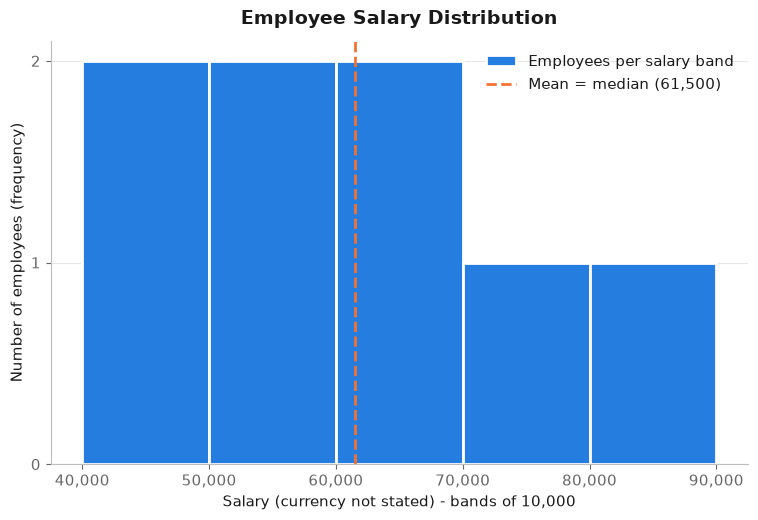

Saved: reports\figures\02_salary_distribution_histogram.png
Insight: Salaries range from 45,000 to 81,000; 6 of 8 employees (75%) earn below 70,000, and mean (61,500) = median (61,500), so the distribution is balanced with no extreme values.


In [6]:
s = df["salary"]
below_70k = (s < 70_000).sum()
insight = (f"Salaries range from {s.min():,.0f} to {s.max():,.0f}; {below_70k} of {len(s)} employees "
           f"({below_70k / len(s):.0%}) earn below 70,000, and mean ({s.mean():,.0f}) = median ({s.median():,.0f}), "
           f"so the distribution is balanced with no extreme values.")
show_and_save(er.plot_salary_histogram, "02_salary_distribution_histogram.png", insight)

## 9. Visualization 3 – Scatter Plot: Salary by City
**Replaces 'experience vs salary'** (no experience column exists). Each point is one employee, labelled with name and department. Grey ticks show the city average; the orange line is the company average.

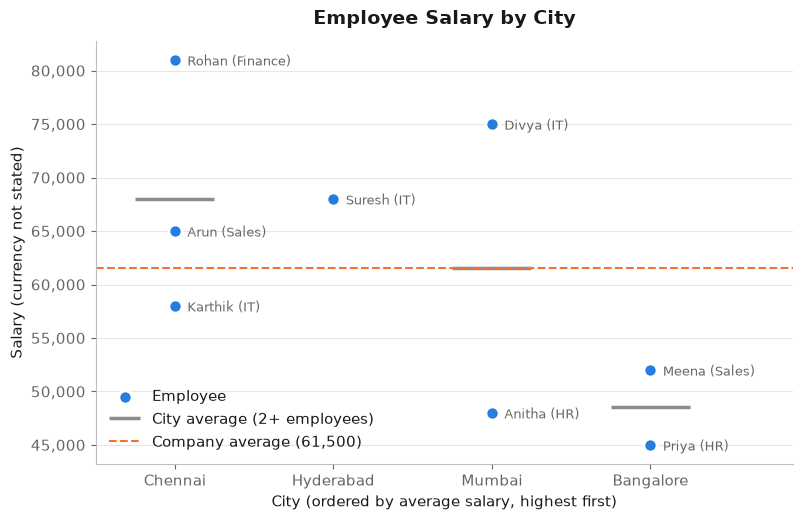

Saved: reports\figures\03_city_salary_scatter.png
Insight: Chennai and Hyderabad have the highest city average (68,000) and Bangalore the lowest (48,500), but Bangalore's staff work in HR and Sales, the lowest-paid departments, so the city gap may come from department mix, not location.


In [7]:
lowest_city = city.index[-1]
lowest_city_depts = sorted(df.loc[df["city"] == lowest_city, "department"].unique())
insight = (f"{' and '.join(city[city['avg_salary'] == city['avg_salary'].max()].index)} have the highest city average "
           f"({city['avg_salary'].max():,.0f}) and {lowest_city} the lowest ({city.loc[lowest_city, 'avg_salary']:,.0f}), "
           f"but {lowest_city}'s staff work in {' and '.join(lowest_city_depts)}, the lowest-paid departments, so the city "
           f"gap may come from department mix, not location.")
show_and_save(er.plot_city_salary_scatter, "03_city_salary_scatter.png", insight)

## 10. Visualization 4 – Line Chart: Payroll Concentration Curve
**Replaces 'hiring trend over time'** (no joining-date column exists). Employees are sorted from lowest to highest salary; the line shows the cumulative share of total payroll. The closer it is to the grey diagonal, the more evenly pay is spread.

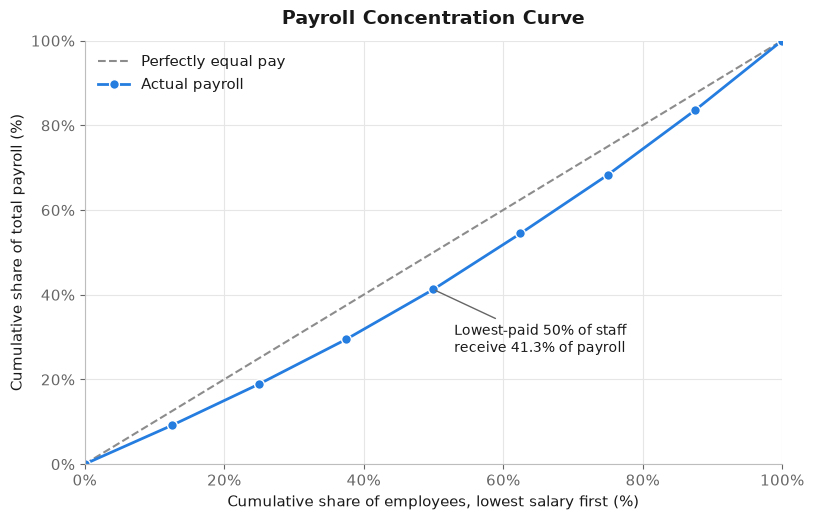

Saved: reports\figures\04_payroll_concentration_line.png
Insight: The lowest-paid 50% of staff receive 41.3% of payroll and the top 25% receive 31.7%; a Gini coefficient of 0.11 (0 = perfectly equal) shows pay is spread fairly evenly.


In [8]:
curve = er.payroll_curve(df)
bottom_half = curve.loc[curve["employee_share"] == 50, "payroll_share"].iloc[0]
top_quarter = 100 - curve.loc[curve["employee_share"] == 75, "payroll_share"].iloc[0]
insight = (f"The lowest-paid 50% of staff receive {bottom_half:.1f}% of payroll and the top 25% receive "
           f"{top_quarter:.1f}%; a Gini coefficient of {er.gini(df):.2f} (0 = perfectly equal) shows pay is spread fairly evenly.")
show_and_save(er.plot_payroll_curve_line, "04_payroll_concentration_line.png", insight)

## 11. Visualization 5 – Box Plot: Salary by Department
Shows the spread of salaries inside each department. Every employee is drawn as a dot because the groups are small. The dotted lines are the company-wide IQR outlier fences from Part 1.

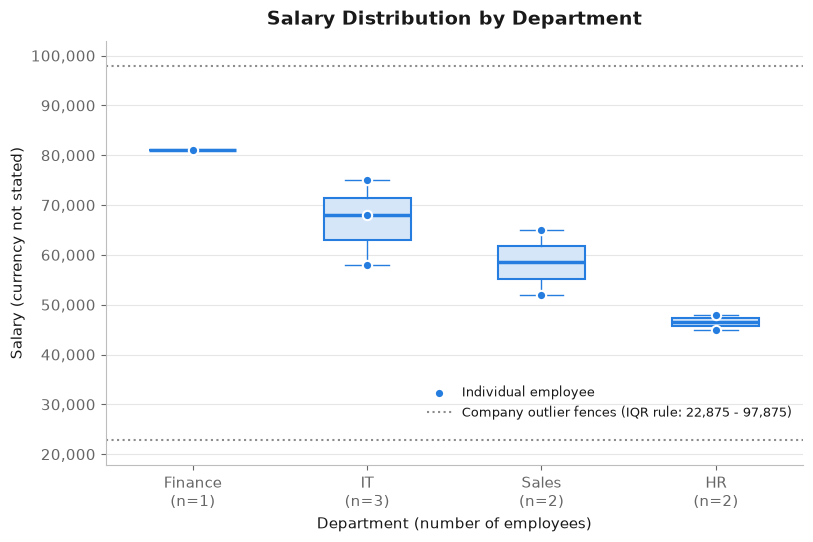

Saved: reports\figures\05_salary_boxplot.png
Insight: 0 salaries fall outside the outlier fences (22,875-97,875); IT has the widest range (17,000) and HR the narrowest (3,000), with every HR salary below every other department's.


In [9]:
spread = (dept["max_salary"] - dept["min_salary"])
multi_spread = spread[dept["employees"] > 1]
insight = (f"{len(outliers)} salaries fall outside the outlier fences ({bounds['lower']:,.0f}-{bounds['upper']:,.0f}); "
           f"{multi_spread.idxmax()} has the widest range ({multi_spread.max():,.0f}) and {multi_spread.idxmin()} the narrowest "
           f"({multi_spread.min():,.0f}), with every {multi_spread.idxmin()} salary below every other department's.")
show_and_save(er.plot_salary_boxplot, "05_salary_boxplot.png", insight)

### Check: all five figure files exist

In [10]:
for path in saved_files:
    print(f"{path.name:42s} {'OK' if path.is_file() else 'MISSING'}  {path.stat().st_size / 1024:,.0f} KB")
assert len(saved_files) == 5 and all(p.is_file() for p in saved_files)

01_department_salary_bar.png               OK  76 KB
02_salary_distribution_histogram.png       OK  59 KB
03_city_salary_scatter.png                 OK  97 KB
04_payroll_concentration_line.png          OK  121 KB
05_salary_boxplot.png                      OK  76 KB


## 12. Key Findings
The numbers are calculated in the cell below. The text underneath interprets them.

In [11]:
company_avg = df["salary"].mean()
hr_gap = company_avg - dept.loc["HR", "avg_salary"]
bottom3 = df.nsmallest(3, "salary")[["name", "department", "salary"]]
findings = pd.DataFrame({
    "metric": ["Employees", "Company average salary", "Highest dept average (Finance, n=1)",
               "Highest dept average with 2+ staff (IT, n=3)", "Lowest dept average (HR, n=2)",
               "HR gap below company average", "Highest / lowest city average",
               "Payroll share of lowest-paid 50%", "Gini coefficient", "IQR outliers"],
    "value": [f"{len(df)}", f"{company_avg:,.0f}", f"{dept.loc['Finance', 'avg_salary']:,.0f}",
              f"{dept.loc['IT', 'avg_salary']:,.0f}", f"{dept.loc['HR', 'avg_salary']:,.0f}",
              f"{hr_gap:,.0f} ({hr_gap / company_avg:.0%})",
              f"{city['avg_salary'].max():,.0f} / {city['avg_salary'].min():,.0f}",
              f"{bottom_half:.1f}%", f"{er.gini(df):.2f}", f"{len(outliers)}"],
})
display(findings)
print("Three lowest salaries:")
display(bottom3)

,metric,value
0,Employees,8
1,Company average salary,"61,500"
2,"Highest dept average (Finance, n=1)","81,000"
3,"Highest dept average with 2+ staff (IT, n=3)","67,000"
4,"Lowest dept average (HR, n=2)","46,500"
5,HR gap below company average,"15,000 (24%)"
6,Highest / lowest city average,"68,000 / 48,500"
7,Payroll share of lowest-paid 50%,41.3%
8,Gini coefficient,0.11
9,IQR outliers,0


Three lowest salaries:


,name,department,salary
1,Priya,HR,45000
7,Anitha,HR,48000
5,Meena,Sales,52000


1. **Department is the clearest driver of pay.** Averages go from 81,000 (Finance, 1 person) and 67,000 (IT) down to
   58,500 (Sales) and 46,500 (HR). HR is **15,000 (24 %) below** the company average of 61,500, and both HR employees are among the three lowest salaries.
2. **Pay is fairly evenly spread, with no outliers.** Mean = median = 61,500, the lowest-paid half of staff receive 41.3 % of payroll,
   the Gini coefficient is 0.11, and 0 salaries fall outside the IQR fences (22,875–97,875).
3. **The city gap probably reflects department mix.** Chennai and Hyderabad average 68,000 and Bangalore 48,500. However, Bangalore's
   two employees work in HR and Sales, the two lowest-paid departments, so with 8 rows we cannot tell location and department apart.

## 13. Recommendations
1. **Review HR salaries against the market.** HR averages 46,500, 24 % below the company average. Both HR staff are in the bottom three salaries.
   Benchmark these roles before it becomes a retention risk.
2. **Collect the missing fields before making pay decisions.** Add *joining date, years of experience, job level* and *salary currency/period*,
   and grow the dataset beyond 8 people. Then the two charts that had to be replaced (experience vs salary, hiring trend) can be built,
   and we can test whether the department and city gaps are explained by seniority.

## 14. Limitations
* **Only 8 employees.** One salary changes a group average a lot. Finance's "highest average" is a single person.
* **No experience or date columns,** so the requested experience scatter and hiring-trend line were replaced with honest alternatives.
* **Only one numeric measure (salary),** so no meaningful correlation analysis is possible.
* **Salary currency and pay period are not stated,** so the charts label salary as "currency not stated".
* The findings describe this sample only. They are not statistically significant.

## 15. Conclusion
The cleaned Part 1 dataset was turned into five labelled, high-resolution charts. They show that **department is the main visible driver
of salary**: HR is clearly the lowest-paid group. Overall pay is evenly spread, with no outliers. The biggest next step is better data
(experience, dates, more employees), so that pay differences can be explained rather than only described.

**Outputs:** all inside `week1/day5/afternoon/`: `reports/figures/*.png` · `reports/summary_report.md` · `reports/analysis_report.html` · `streamlit_app/app.py` · `reports/presentation.md`